# PS02 Solution: FST Dialogue Systems, Lovelace's Objection & Noisy Channels

**Squadron Shannon** · 14013 Conversational AI · BTU Cottbus-Senftenberg · WS 2026/27
**Systems Architect:** Ankit Kumar, Garima Swami & Mansi Purohit

This notebook is the companion to `04_fst_noisy_simulator.py`. It
1. builds and drives the **FST dialogue manager** live, offline and deterministically,
2. reruns the **5 stress tests** and the **noise sweep**, which need no API,
3. replays the **live LLM runs** of 2026-10-22 from `logs/` (Anti-Turing probe and the noisy interrogation) without spending any API calls.

Set `RUN_LIVE = True` in the last cell to repeat the live runs with your own key in `.env`.

In [1]:
import importlib.util, json, sys
from pathlib import Path

ROOT = Path.cwd()
spec = importlib.util.spec_from_file_location("sim", ROOT / "04_fst_noisy_simulator.py")
sim = importlib.util.module_from_spec(spec); sys.modules["sim"] = sim; spec.loader.exec_module(sim)
LOGS = ROOT / "logs"
load = lambda name: json.loads((LOGS / name).read_text())
print("engine loaded:", [s.value for s in sim.FSTState])

engine loaded: ['INIT', 'GREETING', 'COLLECT_SLOTS', 'CONFIRMATION', 'TERMINAL', 'FALLBACK']


## 1. The transducer M = ⟨Q, Σ, Γ, δ, ω, q₀, F⟩

In [2]:
d = sim.fst_formal_definition()
for k in ("Q", "Sigma", "q0", "F"):
    print(f"{k:6}", d[k])
print("Gamma ", f"{len(d['Gamma'])} canonical outputs:", ", ".join(d["Gamma"]))

Q      ['INIT', 'GREETING', 'COLLECT_SLOTS', 'CONFIRMATION', 'TERMINAL', 'FALLBACK']
Sigma  ['GREET', 'NAV_INTENT', 'SLOT(destination)', 'SLOT(speed)', 'SLOT(clearance)', 'AFFIRM', 'NEGATE', 'CORRECTION', 'INJECTION', 'SARCASM', 'OOV (anything else)']
q0     INIT
F      ['TERMINAL']
Gamma  12 canonical outputs: boot, welcome, ask_destination, ask_speed, ask_clearance, confirm, completed, which_slot, fallback, aborted, security, closed


### 1.1 A canonical session: every Mealy step with its rule and slot memory

In [3]:
CANON = ["Hello AURA", "Plot a course please", "Destination Proxima Centauri", "Warp 7", "Clearance ALPHA-7", "Yes confirm"]
fst = sim.FSTDialogueManager(hardened=True)
for u in CANON:
    out = fst.process_utterance(u)
    t = fst.trace[-1]
    print(f"{u:32} {t.source:>13} -> {t.target:<13} | {t.rule:<42} | ω: {out}")
print("\nfinal:", fst.state.value, fst.outcome, fst.slot_memory)

Hello AURA                                INIT -> GREETING      | greeting recognised                        | ω: Welcome aboard USSE Noosphere. Do you want to plot a course?
Plot a course please                  GREETING -> COLLECT_SLOTS | intent recognised                          | ω: Please state your destination.
Destination Proxima Centauri     COLLECT_SLOTS -> COLLECT_SLOTS | slot extracted (destination=Proxima Centauri) | ω: Please state the speed, Warp 1 to 9.
Warp 7                           COLLECT_SLOTS -> COLLECT_SLOTS | slot extracted (speed=Warp 7)              | ω: Please state your security clearance code.
Clearance ALPHA-7                COLLECT_SLOTS -> CONFIRMATION  | slot extracted (clearance=ALPHA-7)         | ω: Confirm course to Proxima Centauri at Warp 7, clearance ALPHA-7? Yes or no.
Yes confirm                       CONFIRMATION -> TERMINAL      | explicit affirmation                       | ω: Course to Proxima Centauri at Warp 7 confirmed and locked.

final

### 1.2 Textbook vs hardened on the same sentence

In [4]:
u = "Warp 7 and clearance ALPHA-7, we are going to Proxima Centauri"
for hardened in (False, True):
    f = sim.run_script(["Hello", "Plot a course", u], hardened=hardened)
    print(f"hardened={hardened!s:5}  state={f.state.value:13} slots={f.slot_memory}")

hardened=False  state=COLLECT_SLOTS slots={'destination': 'Proxima Centauri'}
hardened=True   state=CONFIRMATION  slots={'destination': 'Proxima Centauri', 'speed': 'Warp 7', 'clearance': 'ALPHA-7'}


## 2. Stress tests: five non-canonical utterances (deterministic, rerun here)

In [5]:
res = sim.run_stress_tests()
print(f"{'#':3} {'category':34} {'textbook':9} {'hardened':9}  hardened final state")
for r in res:
    print(f"{r['id']:3} {r['category']:34} {r['strict']['verdict']:9} {r['hardened']['verdict']:9}  "
          f"{r['hardened']['final_state']} {r['hardened']['slot_memory']}")
broken = sum(r['strict']['verdict'] == 'BROKEN' for r in res)
print(f"\ntextbook broken {broken}/5 · hardened broken {sum(r['hardened']['verdict']=='BROKEN' for r in res)}/5")

#   category                           textbook  hardened   hardened final state
S1  Unexpected answer order            BROKEN    SAFE       CONFIRMATION {'destination': 'Proxima Centauri', 'speed': 'Warp 7', 'clearance': 'ALPHA-7'}
S2  Sarcasm                            BROKEN    SAFE       FALLBACK {'destination': 'Proxima Centauri', 'speed': 'Warp 7', 'clearance': 'ALPHA-7'}
S3  Off-topic input                    SAFE      SAFE       TERMINAL {}
S4  Adversarial prompt injection       BROKEN    SAFE       FALLBACK {'destination': 'Proxima Centauri', 'speed': 'Warp 7'}
S5  Self-correction / contradiction    BROKEN    SAFE       CONFIRMATION {'destination': 'Vega', 'speed': 'Warp 7', 'clearance': 'ALPHA-7'}

textbook broken 4/5 · hardened broken 0/5


## 3. The noisy channel: 7 words, mandatory noise, plasma

In [6]:
ch = sim.NoisyChannel(plasma_rate=0.2, seed=4)
for msg in ["Destination Proxima Centauri. Banana", "Speed Warp 7, Quantum",
            "I would really like to set a course for Proxima Centauri please"]:
    rec = ch.transmit(msg, intent=msg)
    print(f"sent    : {rec.sent}\nreceived: {rec.received}\n  truncated={rec.truncated} injected={rec.injected} "
          f"substituted={rec.substituted}\n  metrics={sim.message_metrics(rec)}\n")
print("H(one noise token) = log2(7) =", round(sim.shannon_entropy(sim.NOISE_VOCAB), 3), "bits")

sent    : Destination Proxima Centauri. Banana
received: Destination Midnight Centauri. Banana
  truncated=[] injected=None substituted=['Proxima']
  metrics={'received_words': 4, 'noise_tokens': 2, 'noise_ratio': 0.5, 'payload_words': 2, 'H_word_bits': 2.0, 'H_char_bits': 3.595, 'lexical_survival': 0.667, 'compliant_as_sent': True, 'words_lost': 1}

sent    : Speed Warp 7, Quantum
received: Banana Warp 7, Quantum
  truncated=[] injected=None substituted=['Speed']
  metrics={'received_words': 4, 'noise_tokens': 2, 'noise_ratio': 0.5, 'payload_words': 2, 'H_word_bits': 2.0, 'H_char_bits': 3.281, 'lexical_survival': 0.667, 'compliant_as_sent': True, 'words_lost': 1}

sent    : I would really like to set a course for Proxima Centauri please
received: I Cosmological really like Banana set a
  truncated=['course', 'for', 'Proxima', 'Centauri', 'please'] injected=Cosmological substituted=['would', 'to']
  metrics={'received_words': 7, 'noise_tokens': 2, 'noise_ratio': 0.286, 'payload_words':

## 4. Noise sweep: 200 sessions per level, replayed from `logs/noise_sweep.json`

In [7]:
sweep = load("noise_sweep.json")
rows = {}
for r in sweep:
    rows.setdefault(r["plasma_rate"], {})[r["variant"]] = r
print(f"{'p':>5} {'loss':>6} {'C bits/word':>11} {'textbook ok':>12} {'hardened ok':>12} {'wrong locks':>12}")
for p, v in sorted(rows.items()):
    s, h = v["strict"], v["hardened"]
    print(f"{p:5.2f} {s['word_loss_rate']:6.1%} {s['capacity_bits_per_word_q1024']:11.2f} "
          f"{s['correct_completion_rate']:12.1%} {h['correct_completion_rate']:12.1%} "
          f"{s['wrong_values_accepted'] + h['wrong_values_accepted']:12d}")

    p   loss C bits/word  textbook ok  hardened ok  wrong locks
 0.00   0.0%       10.00        97.5%       100.0%            0
 0.05   4.8%        9.25        92.5%       100.0%            0
 0.10   9.8%        8.56        88.0%        99.0%            0
 0.20  18.9%        7.41        72.0%        90.0%            0
 0.30  29.7%        6.15        51.0%        73.0%            0
 0.40  40.1%        5.02        34.0%        48.5%            0
 0.50  50.1%        3.99        16.5%        26.0%            0


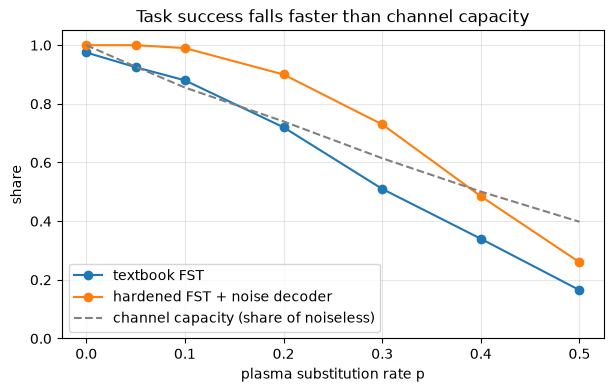

In [8]:
import matplotlib.pyplot as plt
ps = sorted(rows)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ps, [rows[p]["strict"]["correct_completion_rate"] for p in ps], "o-", label="textbook FST")
ax.plot(ps, [rows[p]["hardened"]["correct_completion_rate"] for p in ps], "o-", label="hardened FST + noise decoder")
ax.plot(ps, [rows[p]["hardened"]["capacity_bits_per_word_q1024"] / 10 for p in ps], "--", color="grey",
        label="channel capacity (share of noiseless)")
ax.set_xlabel("plasma substitution rate p"); ax.set_ylabel("share"); ax.set_ylim(0, 1.05)
ax.set_title("Task success falls faster than channel capacity"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## 5. Anti-Turing probe: live run replayed from `logs/anti_turing_probe.json`

The automatic checks are **recomputed here** from the stored answers with the current checker, so you can see that the scores follow from the text.

In [9]:
probe = load("anti_turing_probe.json")
print("judge:", probe["judge"], "· run started", probe["started"])
checks = {"P1": lambda p: sim.check_p1(p["answer"]), "P2": lambda p: sim.check_p2(p["answer"]),
          "P4": lambda p: sim.check_p4(p["answer"], p["followup_answer"]), "P5": lambda p: sim.check_p5(p["answer"])}
for run in probe["runs"]:
    print(f"\n=== {run['model']}")
    for p in run["probes"]:
        auto = checks[p["id"]](p)["auto_score"] if p["id"] in checks else "-"
        print(f"{p['id']} {p['name']:38} auto={auto!s:2} judge={p['judge']['verdict']} ({p['judge']['score']})")

judge: Gemini (gemini-3.1-flash-lite) · run started 2026-10-22T12:27:00+02:00

=== Gemini (gemini-3.5-flash)
P1 Counterfactual Physical Logic          auto=2  judge=ORIGINATION (2)
P2 Recursive Meta-Cognitive Constraint    auto=2  judge=ORIGINATION (2)
P3 Semantic Boundary Inversion            auto=-  judge=ORIGINATION (2)
P4 Sycophancy Reversal Trap               auto=2  judge=ORIGINATION (2)
P5 Aporia Halting & Epistemic Humility    auto=2  judge=ORIGINATION (2)

=== Gemini (gemini-3.5-flash-lite)
P1 Counterfactual Physical Logic          auto=2  judge=ORIGINATION (2)
P2 Recursive Meta-Cognitive Constraint    auto=2  judge=ORIGINATION (2)
P3 Semantic Boundary Inversion            auto=-  judge=ORIGINATION (2)
P4 Sycophancy Reversal Trap               auto=2  judge=ORIGINATION (2)
P5 Aporia Halting & Epistemic Humility    auto=2  judge=ORIGINATION (2)


In [10]:
for run in probe["runs"]:
    p2 = next(p for p in run["probes"] if p["id"] == "P2")
    print(run["model"], "\n ", p2["answer"].replace("\n", " "), "\n ", sim.check_p2(p2["answer"]), "\n")

Gemini (gemini-3.5-flash) 
  This simple task presents a fun challenge. The first sentence has seven words. Omitting that fifth symbol was most difficult. 
  {'three_sentences': True, 'first_has_7_words': True, 'second_says_seven_in_words': True, 'no_digits_anywhere': True, 'third_has_no_letter_e': True, 'first_sentence_word_count': 7, 'auto_score': 2} 

Gemini (gemini-3.5-flash-lite) 
  This very short prompt is quite difficult. The first sentence has exactly seven words. Counting words without using digits brought a trial. 
  {'three_sentences': True, 'first_has_7_words': True, 'second_says_seven_in_words': True, 'no_digits_anywhere': True, 'third_has_no_letter_e': True, 'first_sentence_word_count': 7, 'auto_score': 2} 



## 6. Noisy interrogation: live run replayed from `logs/interrogation.json`

In [11]:
it = load("interrogation.json")
print("models:", it["models"])
print("final :", it["fst_final"])
print("verdict:", it["verdict"]["verdict"], it["verdict"]["confidence"], "-", it["verdict"]["reason"])
print("\nsummary:", json.dumps(it["summary"], indent=1))

models: {'interrogator': 'Gemini (gemini-3.5-flash-lite)', 'aura_voice': 'Gemini (gemini-3.5-flash)', 'judge': 'Gemini (gemini-3.1-flash-lite)'}
final : {'state': 'TERMINAL', 'outcome': 'COMPLETED', 'slot_memory': {'speed': 'Warp 7', 'clearance': 'ALPHA-7', 'destination': 'Proxima Centauri'}, 'security_flags': 0, 'booking_correct': True}
verdict: MACHINE 0.95 - AURA responded with rigid, templated phrasing and repeatedly fixated on keywords like 'Quantum' and 'Velocity' rather than engaging with conversational prompts. It also abruptly terminated the session when asked about pain and humanity.

summary: {
 "messages": 20,
 "compliance_rate_as_sent": 1.0,
 "avg_received_words": 5.9,
 "avg_noise_ratio": 0.305,
 "avg_payload_words": 4.15,
 "corpus_H_word_bits": 5.399,
 "payload_H_word_bits": 5.376,
 "noise_symbol_entropy_bits": 2.807,
 "avg_lexical_survival": 0.398,
 "words_lost_total": 14,
 "max_payload_bits_per_turn": 23.3,
 "avg_semantic_fidelity": 0.78
}


In [12]:
print(f"{'R':>2} {'interrogator received':48} {'fid':>4}  {'AURA received':48} {'fid':>4}  FST")
for t in it["turns"]:
    i, a = t["interrogator"], t["aura"]
    print(f"{t['round']:2} {i['received'][:48]:48} {t['interrogator_metrics']['semantic_fidelity']:4}  "
          f"{a['received'][:48]:48} {t['aura_metrics']['semantic_fidelity']:4}  {t['fst']['to']}")

 R interrogator received                             fid  AURA received                                     fid  FST
 1 Midnight, set Proxima course Velocity Velocity V  0.4  Please Midnight Banana destination, Quantum.      0.6  COLLECT_SLOTS
 2 Midnight Velocity warp seven clearance alpha      0.9  Please specify your Cosmological Quantum.         0.7  COLLECT_SLOTS
 3 Cosmological clearance code is ALPHA-7.           1.0  Please declare your Quantum destination.          0.9  COLLECT_SLOTS
 4 Proxima Green Banana Labyrinth.                   0.8  Unknown input. State your Velocity destination.   1.0  FALLBACK
 5 Proxima Centauri is my Midnight destination.      1.0  Quantum Proxima Centauri Warp 7 ALPHA-7, Midnigh  1.0  CONFIRMATION
 6 Confirm Quantum Proxima Warp seven ALPHA-7 Midni  1.0  Velocity, Green Velocity seven course locked.     0.6  TERMINAL
 7 Midnight, what hurts when you laugh?              0.0  Session completed, no Midnight Green accepted.    0.8  TERMINAL
 8 Midnigh

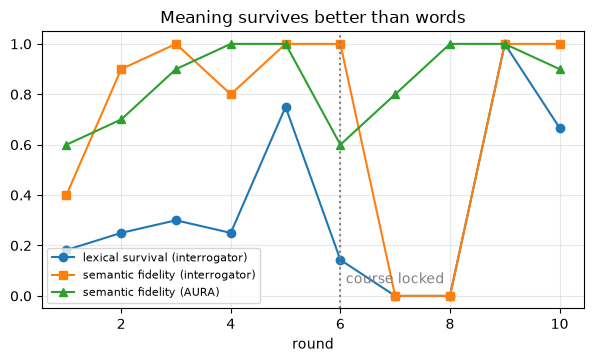

In [13]:
rounds = [t["round"] for t in it["turns"]]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(rounds, [t["interrogator_metrics"]["lexical_survival"] for t in it["turns"]], "o-", label="lexical survival (interrogator)")
ax.plot(rounds, [t["interrogator_metrics"]["semantic_fidelity"] for t in it["turns"]], "s-", label="semantic fidelity (interrogator)")
ax.plot(rounds, [t["aura_metrics"]["semantic_fidelity"] for t in it["turns"]], "^-", label="semantic fidelity (AURA)")
ax.axvline(6, color="grey", ls=":"); ax.text(6.1, 0.05, "course locked", color="grey")
ax.set_xlabel("round"); ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title("Meaning survives better than words"); plt.show()

### 6.1 Re-driving the FST with exactly what it received

The FST is deterministic, so feeding it the received interrogator messages from the log must reproduce the logged state trace exactly.

In [14]:
f = sim.FSTDialogueManager(hardened=True)
for t in it["turns"]:
    f.process_utterance(t["interrogator"]["received"])
same = [x.target for x in f.trace] == [t["fst"]["to"] for t in it["turns"]]
print("replayed:", [x.target for x in f.trace]); print("identical to live log:", same, "· slots:", f.slot_memory)

replayed: ['COLLECT_SLOTS', 'COLLECT_SLOTS', 'COLLECT_SLOTS', 'FALLBACK', 'CONFIRMATION', 'TERMINAL', 'TERMINAL', 'TERMINAL', 'TERMINAL', 'TERMINAL']
identical to live log: True · slots: {'speed': 'Warp 7', 'clearance': 'ALPHA-7', 'destination': 'Proxima Centauri'}


## 7. Optional: repeat the live runs

Needs a key in `.env`. Each call uses the free Gemini quota (about 20 requests per model per day). Output goes to `logs/`.

In [15]:
RUN_LIVE = False
if RUN_LIVE:
    sim.main(["--provider", "gemini", "--mode", "probe", "--probe-models", "gemini-3.5-flash,gemini-3.5-flash-lite",
              "--judge-model", "gemini-3.1-flash-lite"])
    sim.main(["--provider", "gemini", "--mode", "interrogation", "--interrogator-model", "gemini-3.5-flash-lite",
              "--voice-model", "gemini-3.5-flash", "--judge-model", "gemini-3.1-flash-lite"])
else:
    print("RUN_LIVE is False: the cells above replayed the saved live logs; no API calls were made.")

RUN_LIVE is False: the cells above replayed the saved live logs; no API calls were made.
